Assignment 6. Design and implement a Convolutional Neural Network (CNN) for image classification using the Tomato or Soybean disease dataset.

In [ ]:
!pip install -q -U kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 1.7 MB/s eta 0:00:00


In [ ]:
!kaggle auth login


Go to the following link in your browser, and complete the sign-in prompts at Kaggle:

  https://www.kaggle.com/api/v1/oauth2/authorize?response_type=code&client_id=kagglesdk&redirect_uri=https%3A%2F%2Fwww.kaggle.com%2Faccount%2Fapi%2Foauth%2Ftoken&scope=resources.admin%3A%2A&state=239e63c5-9e24-4cd8-ab6f-0793b58691c4&code_challenge=Vw4ma1aKA21zCfa4jzOsrz65eHCzvNx2SZ3LNP630bk%3D&code_challenge_method=S256&response_mode=query

Once finished, enter the verification code provided in your browser: CfDJ8GNxPX3qpaJEpxfoBSRBZPf2rFs_lVnswzen5TD2YOD-pwsqs7QMUycrNYwp5yUCyipcgwd2p3mn374oMh5QrktGS40hWRLlMZbis2edZ2BwtyLsITuv-Q4Z4SM0vJQQA7TZKQqeBD-FuHKdyBoYxen0vRo1_Ct3loAGjl5L_loKvkFpWQNrgxkjn8_JiZC6dMwmpDcG6CRW5XxJHnag6rVwx7_z3Tk1M2590TvtC_04_K4nlDvVwJqFt4JXH9HqIDvE77yESTxK1rCtTrGOgI8a9-0I7PY-BVEmxdoUncIVTwctNtkrEEmmiHKhklOf6j2JTG_m985s5KuwdrRMgvKhHLfs6YY

You are now logged in as [saachilaturiya]



In [ ]:
!kaggle auth status

usage: kaggle auth [-h] {login,print-access-token,revoke} ...
kaggle auth: error: argument command: invalid choice: 'status' (choose from login, print-access-token, revoke)


In [ ]:
!kaggle datasets download -d vipoooool/new-plant-diseases-dataset

Dataset URL: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset
License(s): copyright-authors
100% 2.70G/2.70G [00:15<00:00, 192MB/s]



In [ ]:
!rm -rf plant_dataset
!mkdir plant_dataset

!unzip -q new-plant-diseases-dataset.zip -d plant_dataset

In [ ]:
import glob

train_paths = glob.glob(
    "/content/plant_dataset/**/train",
    recursive=True
)

valid_paths = glob.glob(
    "/content/plant_dataset/**/valid",
    recursive=True
)

print("Train:", train_paths)
print("Valid:", valid_paths)

Train: ['/content/plant_dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train', '/content/plant_dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/train']
Valid: ['/content/plant_dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid', '/content/plant_dataset/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid']


In [ ]:
train_dir = train_paths[0]
valid_dir = valid_paths[0]

print("\nTrain directory:", train_dir)
print("Validation directory:", valid_dir)


Train directory: /content/plant_dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train
Validation directory: /content/plant_dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense
)

from sklearn.metrics import confusion_matrix, classification_report

img_size = (64, 64)
batch_size = 64

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=img_size,
    batch_size=batch_size,
    shuffle=True,
    seed=42
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    image_size=img_size,
    batch_size=batch_size,
    shuffle=False
)

class_names = train_ds.class_names

print("Number of Classes:", len(class_names))
print(class_names)

Found 70295 files belonging to 38 classes.
Found 17572 files belonging to 38 classes.
Number of Classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Lea

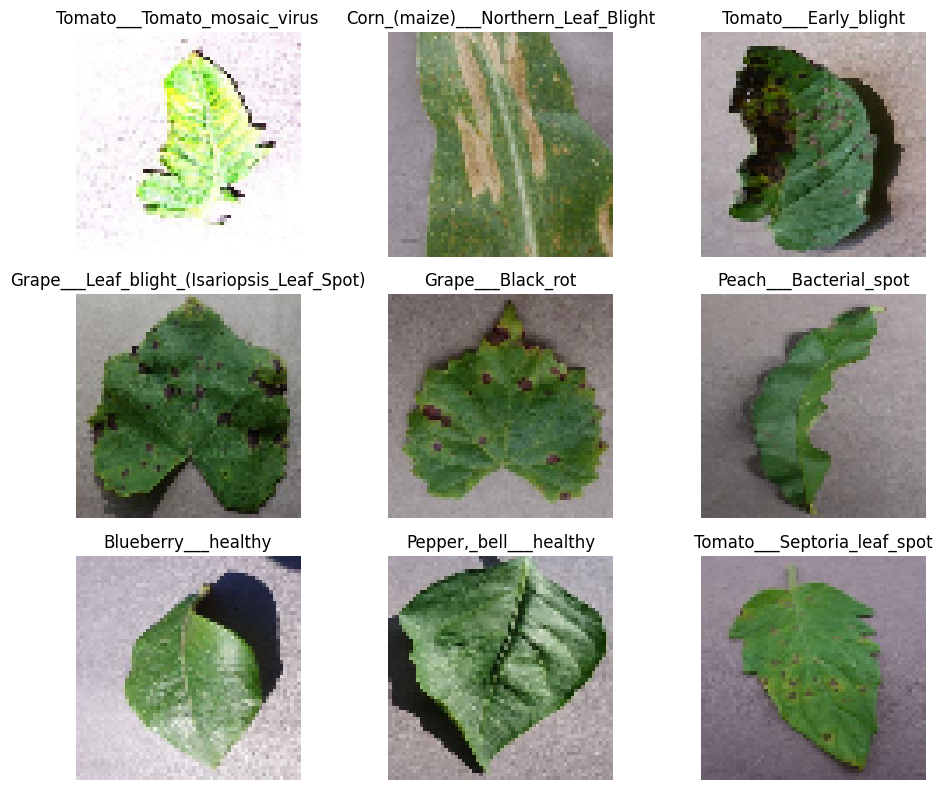

In [ ]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import matplotlib.pyplot as plt

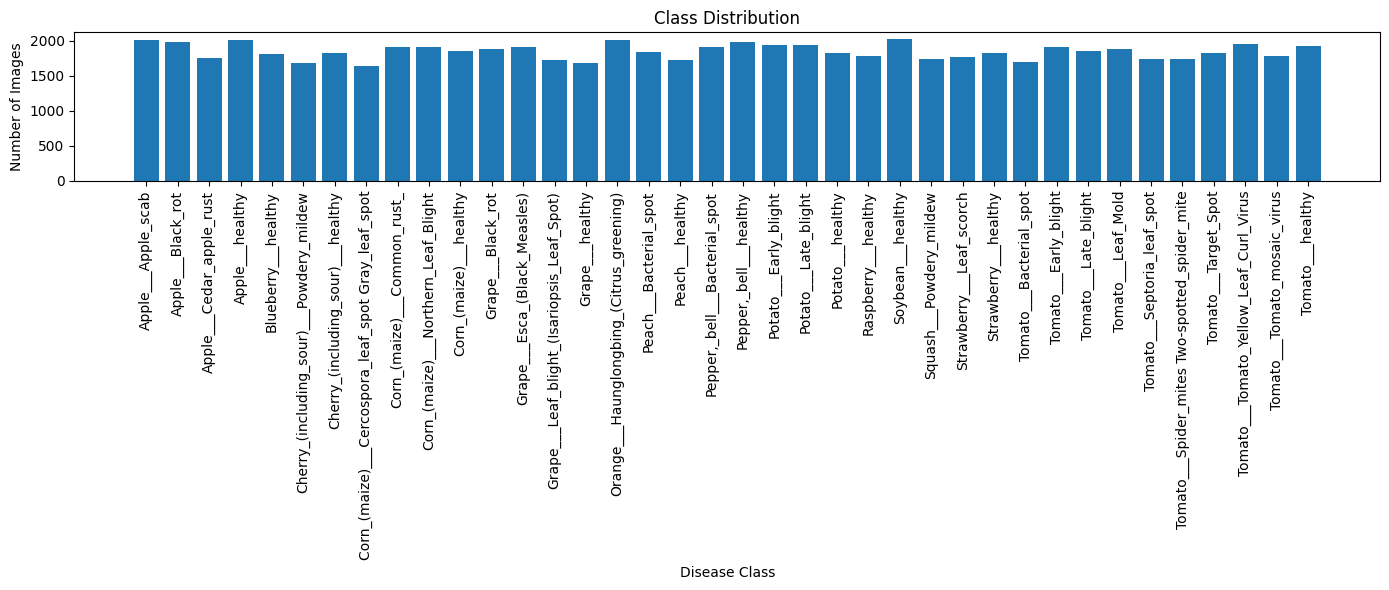

In [ ]:
class_counts = {}

for class_name in class_names:
    class_path = os.path.join(train_dir, class_name)

    count = len([
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

    class_counts[class_name] = count

plt.figure(figsize=(14, 6))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.title("Class Distribution")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

valid_ds = valid_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
valid_ds = valid_ds.prefetch(AUTOTUNE)

In [ ]:
model = Sequential([
    Conv2D(16, (3, 3), activation='relu', input_shape=(64, 64, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    GlobalAveragePooling2D(),

    Dense(64, activation='relu'),

    Dense(len(class_names), activation='softmax')
])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         2,470 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,214 (118.02 KB)

 Trainable params: 30,214 (118.02 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=5
)

Epoch 1/5
1099/1099 ━━━━━━━━━━━━━━━━━━━━ 321s 290ms/step - accuracy: 0.3176 - loss: 2.3755 - val_accuracy: 0.5174 - val_loss: 1.6056
Epoch 2/5
1099/1099 ━━━━━━━━━━━━━━━━━━━━ 335s 304ms/step - accuracy: 0.5710 - loss: 1.4086 - val_accuracy: 0.6234 - val_loss: 1.2151
Epoch 3/5
1099/1099 ━━━━━━━━━━━━━━━━━━━━ 371s 295ms/step - accuracy: 0.6564 - loss: 1.1091 - val_accuracy: 0.6168 - val_loss: 1.2358
Epoch 4/5
1099/1099 ━━━━━━━━━━━━━━━━━━━━ 327s 298ms/step - accuracy: 0.7078 - loss: 0.9337 - val_accuracy: 0.7159 - val_loss: 0.9091
Epoch 5/5
1099/1099 ━━━━━━━━━━━━━━━━━━━━ 333s 303ms/step - accuracy: 0.7462 - loss: 0.7993 - val_accuracy: 0.7614 - val_loss: 0.7550


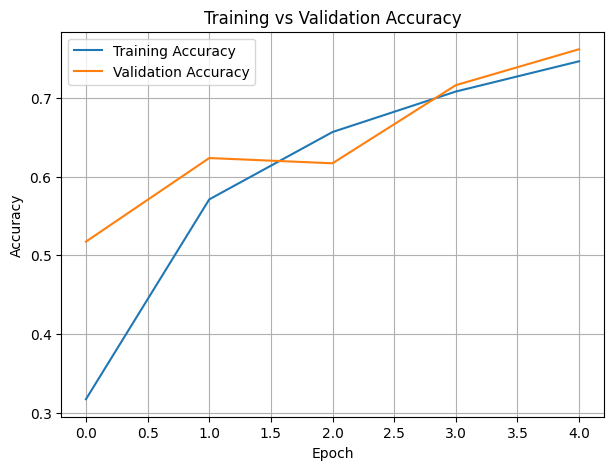

In [ ]:
plt.figure(figsize=(7, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.grid(True)

plt.show()

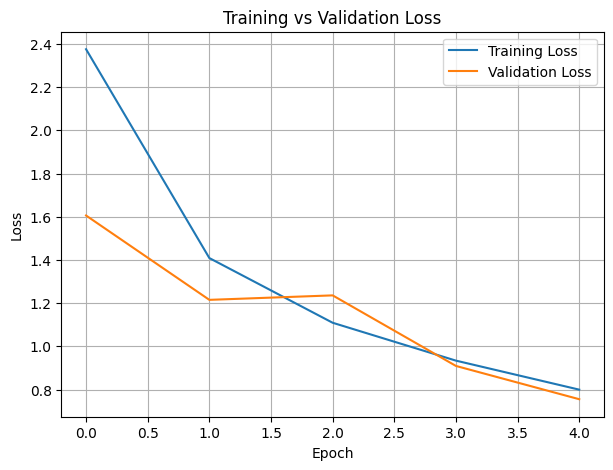

In [ ]:
plt.figure(figsize=(7, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
loss, accuracy = model.evaluate(valid_ds)

print("Validation Accuracy:", accuracy)
print("Validation Loss:", loss)

275/275 ━━━━━━━━━━━━━━━━━━━━ 31s 112ms/step - accuracy: 0.7614 - loss: 0.7550
Validation Accuracy: 0.7614386677742004
Validation Loss: 0.755033016204834


In [ ]:
y_true = []
y_pred = []

for images, labels in valid_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [ ]:
print("Classification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

Classification Report:

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.63      0.80      0.71       504
                                 Apple___Black_rot       0.80      0.79      0.79       497
                          Apple___Cedar_apple_rust       0.69      0.60      0.64       440
                                   Apple___healthy       0.82      0.61      0.70       502
                               Blueberry___healthy       0.75      0.87      0.81       454
          Cherry_(including_sour)___Powdery_mildew       0.53      0.82      0.64       421
                 Cherry_(including_sour)___healthy       0.90      0.88      0.89       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.72      0.65      0.68       410
                       Corn_(maize)___Common_rust_       0.95      0.95      0.95       477
               Corn_(maize)___Northern_Leaf_Blight     

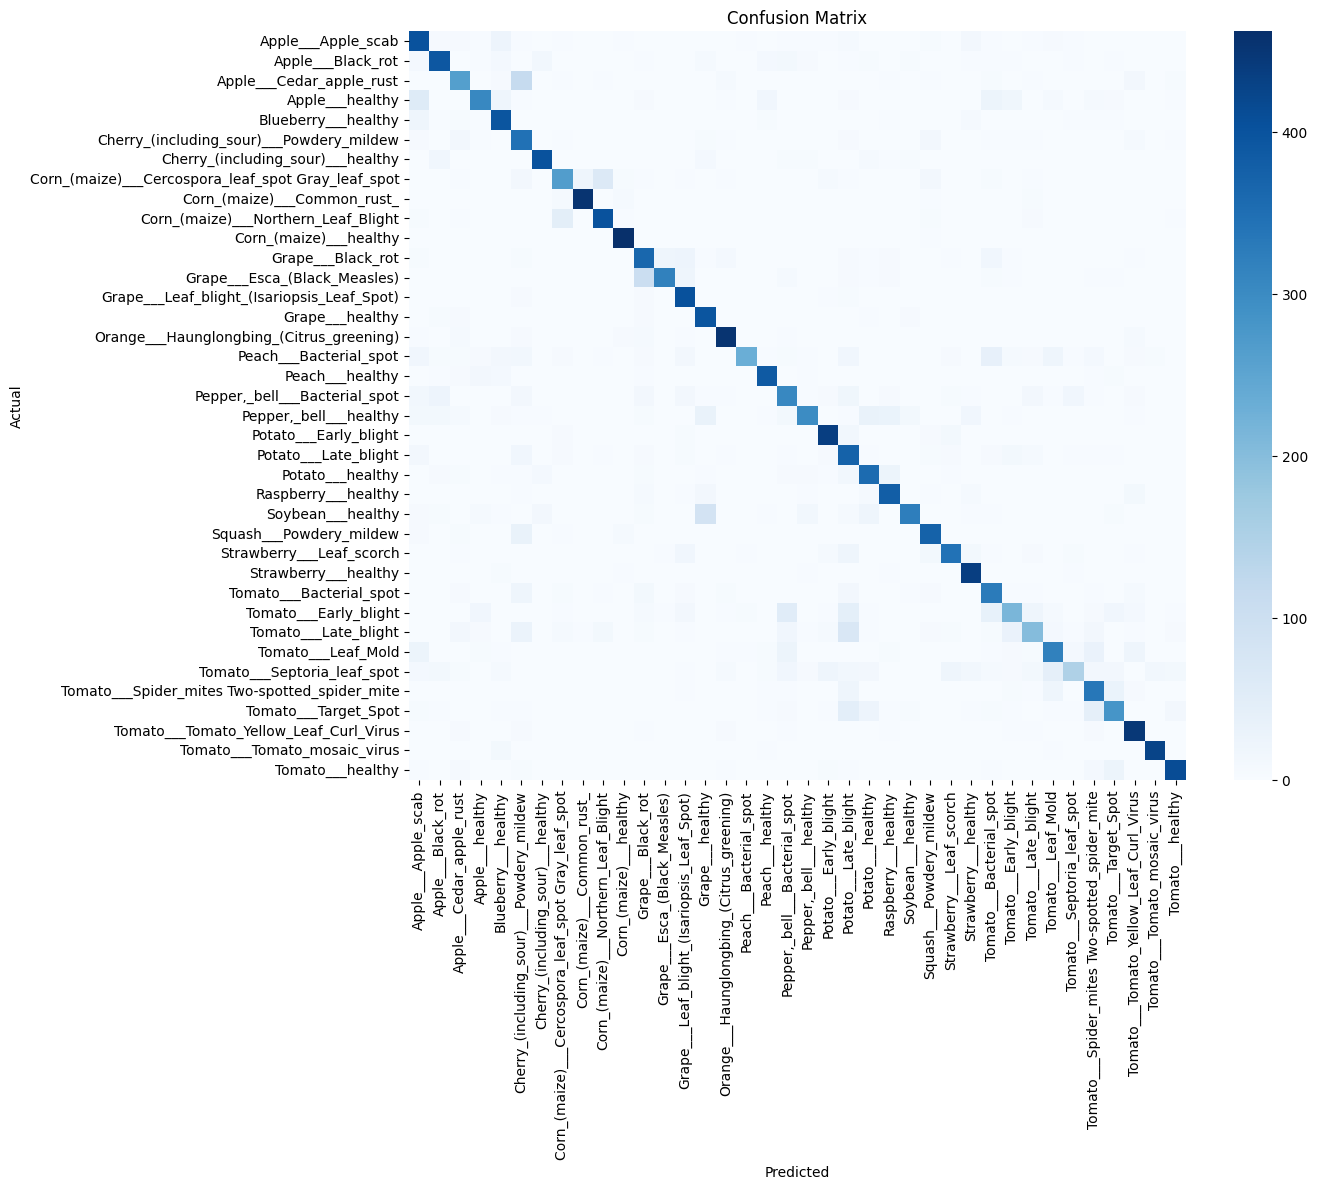

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))

sns.heatmap(
    cm,
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()